# EDA de facturas y conceptos


Este notebook realiza un análisis exploratorio de las facturas y sus conceptos a partir de las categorías para conocer qué compras contiene el conjunto de datos, cómo se distribuyen las categorías y qué problemas de calidad deben tenerse en cuenta antes de la limpieza.

Se revisan aspectos como la cobertura, los duplicados, el gasto, la evolución temporal, las descripciones y la información disponible en las facturas.


In [1]:
%pip install -q pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import unicodedata
from collections import Counter
from decimal import Decimal
from hashlib import sha256
from pathlib import Path
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
import spacy

In [3]:
candidates = [
    candidate
    for parent in (Path.cwd(), *Path.cwd().parents)
    for candidate in (parent, parent / "ecuador-einvoice-classifier")
]

PROJECT_DIR = next(
    (p for p in candidates if (p / "ml/notebooks/01_data_extractor.ipynb").is_file()),
    None,
)

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Abre el notebook desde el proyecto o su carpeta de trabajo."
    )

ML_DIR = PROJECT_DIR / "ml"

In [4]:
DATA_DIR = ML_DIR / "data/extracted"
REPORTS_DIR = ML_DIR / "outputs/reports"
FIGURES_DIR = ML_DIR / "outputs/figures/eda"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Facturas originales
raw_invoices = pd.read_parquet(DATA_DIR / "invoices.parquet")

# Conceptos etiquetados
raw_invoice_items = pd.read_parquet(DATA_DIR / "details.parquet")

# Ids unicos de facturas
dataset_ids = raw_invoices["dataset_archive_sha256"].unique()

if len(dataset_ids) != 1:
    raise ValueError("Las tablas no pertenecen a un único paquete de extracción.")

dataset_id = dataset_ids[0]

if (
    sha256((ML_DIR / "data/invoices_dataset.zip").read_bytes()).hexdigest()
    != dataset_id
):
    raise ValueError(
        "El paquete cambió después de la extracción. Ejecuta de nuevo el notebook 01."
    )

print(
    f"Total archivos: {len(raw_invoices):,} - Total conceptos etiquetados: {len(raw_invoice_items):,}."
)

Total archivos: 7,225 - Total conceptos etiquetados: 22,796.


In [4]:
display(raw_invoices.head())


,source_file_id,source_file_path,dataset_archive_sha256,anonymized_access_key,source_xml_sha256,invoice_body_sha256,invoice_version,issue_date_raw,raw_currency,original_item_count,net_total_raw,net_total,total_discount_raw,total_discount,invoice_total_raw,invoice_total,tip_raw,tip,tax_amount,issue_date
0,b95f1f5c4efa8c798e421121,anonymized_invoices/doc_00000001.xml,f0386e8e11272165dbf2c3a6259088cc48390abfd1e672...,15aa754f03da8ba6c6dcbc1f0fa64d1bffcf718398c448...,af5c37ebda9fa96989375f9459add8807836367141c167...,9e8ce12e13c1380875a177431e6390071b51cb4da56906...,1.0.0,03/04/2022,DOLAR,2,14.00,14.000000,0.00,0.000000,15.68,15.680000,00.00,0.000000,1.680000,2022-04-03
1,44c5da4663ab385cac6e6f7e,anonymized_invoices/doc_00000002.xml,f0386e8e11272165dbf2c3a6259088cc48390abfd1e672...,60d623ca8943c6f8788e4e34352002225b7cb63303b69c...,c507f33daabb2a6829c93b55aceb44e0209d2195dd4b81...,9a2dfaa7bc374ec76c1a8f7b984b7744117fb17dd84792...,1.1.0,09/04/2022,DOLAR,3,3.86,3.860000,0.09,0.090000,4.32,4.320000,0.00,0.000000,0.460000,2022-04-09
2,45615759d270d0c7ff7c733f,anonymized_invoices/doc_00000003.xml,f0386e8e11272165dbf2c3a6259088cc48390abfd1e672...,f5c0ae49445f745e662563c8142a3ef63995fffced2067...,d23c1bd6e0a00c748a798064d3e0f200da526f6dda3dd7...,9b220f310ab2cfbcdfcfecf41ef44d75dd37c451185462...,2.1.0,11/04/2022,DOLAR,1,0.7,0.700000,0.01,0.010000,0.78,0.780000,0,0.000000,0.080000,2022-04-11
3,5cadfe96351b053a57633960,anonymized_invoices/doc_00000004.xml,f0386e8e11272165dbf2c3a6259088cc48390abfd1e672...,82d3ea7ce0cc777877cf3f165ec43eb7eef99faf93c6df...,714b48d7ccc5d3d790311a2b58b6b9abeb8a84c93da016...,ab61879e8693b380bf2552b6f4642b4729ffd2753badd6...,1.1.0,12/04/2022,DOLAR,2,2.16,2.160000,0.00,0.000000,2.42,2.420000,0.00,0.000000,0.260000,2022-04-12
4,f088727d81a6b012f105700a,anonymized_invoices/doc_00000005.xml,f0386e8e11272165dbf2c3a6259088cc48390abfd1e672...,ec55e9f31055b23333330c883bcb32de24808dd07faa29...,973e7d9467bd49ac974ebe2f3bc6ddc4dbd79b5399e331...,6b56a9735e30d41f77a01c4b4cd64b2cc81bd323461694...,1.0.0,13/04/2022,DOLAR,1,0.51,0.510000,0.00,0.000000,0.57,0.570000,0.00,0.000000,0.060000,2022-04-13


In [5]:
display(raw_invoice_items.head())


,source_file_id,source_file_path,anonymized_access_key,item_position,raw_description,product_code,auxiliary_product_code,additional_item_attributes,quantity_raw,quantity,unit_price_raw,unit_price,discount_raw,discount,line_total_raw,line_total,tax_amount,category
0,b95f1f5c4efa8c798e421121,anonymized_invoices/doc_00000001.xml,15aa754f03da8ba6c6dcbc1f0fa64d1bffcf718398c448...,1,Cargo de Reactivación por Mora,1467718198708857466,,ExImpuestos: [VALOR_ANONIMIZADO],1,1.00000000,2.00,2.00000000,0.00,0.000000,2.00,2.000000000000,0.240000,Otros
1,b95f1f5c4efa8c798e421121,anonymized_invoices/doc_00000001.xml,15aa754f03da8ba6c6dcbc1f0fa64d1bffcf718398c448...,2,PLAN CONEXION PAGO ANTICIPADO 12,100031017,,ExImpuestos: [VALOR_ANONIMIZADO],1,1.00000000,12.00,12.00000000,0.00,0.000000,12.00,12.000000000000,1.440000,Otros
2,44c5da4663ab385cac6e6f7e,anonymized_invoices/doc_00000002.xml,60d623ca8943c6f8788e4e34352002225b7cb63303b69c...,1,CLORO LEON 150 CC,7861085700017,7861085700017,,22.000000,22.00000000,0.113482,0.11348200,0.00,0.000000,2.50,2.500000000000,0.300000,Otros
3,44c5da4663ab385cac6e6f7e,anonymized_invoices/doc_00000002.xml,60d623ca8943c6f8788e4e34352002225b7cb63303b69c...,2,GUITIG 3 LT,759494003935,759494003935,,1.000000,1.00000000,1.273125,1.27312500,0.00,0.000000,1.27,1.270000000000,0.150000,Alimentación
4,44c5da4663ab385cac6e6f7e,anonymized_invoices/doc_00000002.xml,60d623ca8943c6f8788e4e34352002225b7cb63303b69c...,3,COLOMBINA WAFER UND,25,25,,2.000000,2.00000000,0.089286,0.08928600,0.09,0.090000,0.09,0.090000000000,0.010000,Alimentación


In [7]:
CATEGORIES = [
    "Alimentación",
    "Salud",
    "Educación, Arte y Cultura",
    "Vivienda",
    "Vestimenta",
    "Turismo Nacional",
    "Otros",
]

In [8]:
COLORS = dict(
    zip(
        CATEGORIES,
        ["#287b70", "#af5369", "#8065a5", "#b18035", "#527fa7", "#44949b", "#737d8c"],
    )
)

plt.rcParams.update(
    {
        "figure.figsize": (11, 5),
        "figure.dpi": 110,
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlesize": 13,
        "axes.labelcolor": "#334155",
        "text.color": "#1e293b",
        "axes.edgecolor": "#cbd5e1",
        "grid.color": "#e2e8f0",
    }
)


def generate_and_save_figure(fig, name: str) -> None:
    """Muestra y guarda la figura."""
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

    plt.show()
    plt.close(fig)


def short_label(value: str) -> str:
    """Versión corta de la categoría para mostrar en gráficos."""
    return value.replace("Educación, Arte y Cultura", "Educación, Arte\ny Cultura")

In [9]:
def category_bars(series: pd.Series, title: str, xlabel: str, name: str) -> None:
    """Compara categorías con una escala y una paleta coherentes."""
    values = series.sort_values()
    fig, ax = plt.subplots(figsize=(11, 5))

    bars = ax.barh(
        [short_label(c) for c in values.index],
        values,
        color=[COLORS[c] for c in values.index],
    )

    ax.bar_label(
        bars,
        labels=[f"{v:,.1f}" if isinstance(v, float) else f"{v:,}" for v in values],
        padding=5,
    )
    ax.set(title=title, xlabel=xlabel)
    ax.set_xlim(0, max(values.max() * 1.18, 1))
    ax.grid(axis="x", alpha=0.65)
    ax.set_axisbelow(True)

    generate_and_save_figure(fig, name)

## 1. Observaciones que representan compras distintas


Primero se cuenta el total de archivos recibidos y se identifican las copias exactas de una misma factura.

Para analizar las compras se utiliza una sola copia por comprobante.


In [10]:
ordered_invoices = raw_invoices.sort_values("source_file_path")
copy_mask = ordered_invoices.duplicated(
    ["anonymized_access_key", "source_xml_sha256"], keep="first"
)
copies = ordered_invoices.loc[copy_mask].copy()
invoices = ordered_invoices.loc[~copy_mask].copy()

invoice_items = raw_invoice_items.loc[
    raw_invoice_items["source_file_id"].isin(invoices["source_file_id"])
].copy()
invoice_items = invoice_items.sort_values(
    ["source_file_id", "item_position"]
).reset_index(drop=True)

identity_variants = raw_invoices.groupby("anonymized_access_key")["invoice_body_sha256"].nunique()
conflict_count = int(identity_variants.gt(1).sum())

display(
    pd.DataFrame(
        {
            "Vista": [
                "Registros originales",
                "Registros sin facturas duplicadas",
                "Registros excluidos por duplicación de facturas",
            ],
            "Facturas": [
                len(raw_invoices),
                len(invoices),
                len(copies),
            ],
            "Conceptos": [
                len(raw_invoice_items),
                len(invoice_items),
                len(raw_invoice_items) - len(invoice_items),
            ],
        }
    )
)

,Vista,Facturas,Conceptos
0,Registros originales,7225,22796
1,Registros sin facturas duplicadas,7204,22754
2,Registros excluidos por duplicación de facturas,21,42


## 2. Relación entre conceptos, categorías e importes


In [11]:
orphan_count = int(
    (~raw_invoice_items["source_file_id"].isin(raw_invoices["source_file_id"])).sum()
)

coverage = pd.DataFrame(
    {
        "Comprobación": [
            "Conceptos sin categoría",
            "Categorías fuera del catálogo",
            "Claves de línea repetidas",
            "Conceptos sin factura",
            "Fechas no interpretables",
            "Importes netos no interpretables",
        ],
        "Registros": [
            raw_invoice_items["category"].isna().sum(),
            (~raw_invoice_items["category"].isin(CATEGORIES)).sum(),
            raw_invoice_items.duplicated(["source_file_path", "item_position"]).sum(),
            orphan_count,
            raw_invoices["issue_date"].isna().sum(),
            raw_invoice_items["line_total"].isna().sum(),
        ],
    }
)

display(coverage)


,Comprobación,Registros
0,Conceptos sin categoría,0
1,Categorías fuera del catálogo,0
2,Claves de línea repetidas,0
3,Conceptos sin factura,0
4,Fechas no interpretables,0
5,Importes netos no interpretables,0


In [12]:
if orphan_count or not raw_invoice_items["category"].isin(CATEGORIES).all():
    raise ValueError(
        "Existen conceptos sin factura o con categorías fuera del catálogo, lo que impide continuar con el análisis."
    )

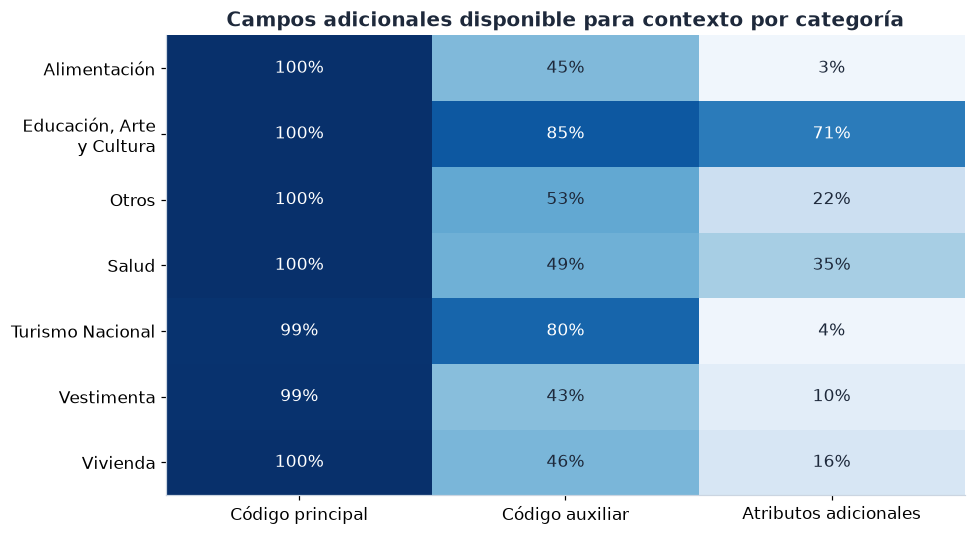

In [13]:
optional_coverage = invoice_items.groupby("category", observed=True).agg(
    product_code=("product_code", lambda s: s.ne("").mean() * 100),
    auxiliary_product_code=("auxiliary_product_code", lambda s: s.ne("").mean() * 100),
    additional_item_attributes=("additional_item_attributes", lambda s: s.ne("").mean() * 100),
)

fig, ax = plt.subplots(figsize=(9, 5))

image = ax.imshow(
    optional_coverage.to_numpy(), cmap="Blues", vmin=0, vmax=100, aspect="auto"
)

ax.set_xticks(
    range(3), ["Código principal", "Código auxiliar", "Atributos adicionales"]
)
ax.set_yticks(
    range(len(optional_coverage)), [short_label(c) for c in optional_coverage.index]
)

for row, values in enumerate(optional_coverage.to_numpy()):
    for col, value in enumerate(values):
        ax.text(
            col,
            row,
            f"{value:.0f}%",
            ha="center",
            va="center",
            color="white" if value > 65 else "#1e293b",
        )

ax.set_title("Campos adicionales disponible para contexto por categoría")

generate_and_save_figure(fig, "01_context_coverage")

In [14]:
def clean_text(value: str) -> str:
    """Transforma texto a formato Unicode y espacios sin borrar números, unidades ni signos."""
    return " ".join(unicodedata.normalize("NFKC", value).split())


def comparison_text(value: str) -> str:
    """Agrupa variantes para diagnóstico; no es el texto de entrada del modelo."""
    folded = unicodedata.normalize("NFKD", clean_text(value).upper())
    folded = "".join(char for char in folded if not unicodedata.combining(char))

    key = " ".join(re.findall(r"[^\W_]+", folded))

    return key or "literal:" + clean_text(value)

In [15]:
invoice_items["description_comparison_text"] = invoice_items["raw_description"].map(comparison_text)
invoice_items["normalized_description"] = invoice_items["raw_description"].map(clean_text)

category_order = invoice_items["category"].value_counts().index.tolist()

class_profile = (
    invoice_items.groupby("category", observed=True)
    .agg(
        concepts=("category", "size"),
        invoices=("source_file_id", "nunique"),
        unique_texts=("description_comparison_text", "nunique"),
    )
    .reindex(category_order)
)
class_profile["share_pct"] = class_profile["concepts"] / len(invoice_items) * 100
class_profile["recurrence_pct"] = (
    1 - class_profile["unique_texts"] / class_profile["concepts"]
) * 100

## 3. Distribucción de conceptos y facturas por categoría


La cantidad de conceptos refleja la frecuencia de las compras, mientras que las descripciones distintas permiten conocer la diversidad de productos o servicios de cada categoría. Además, una factura puede contabilizarse en varias categorías cuando contiene conceptos de diferentes rubros.


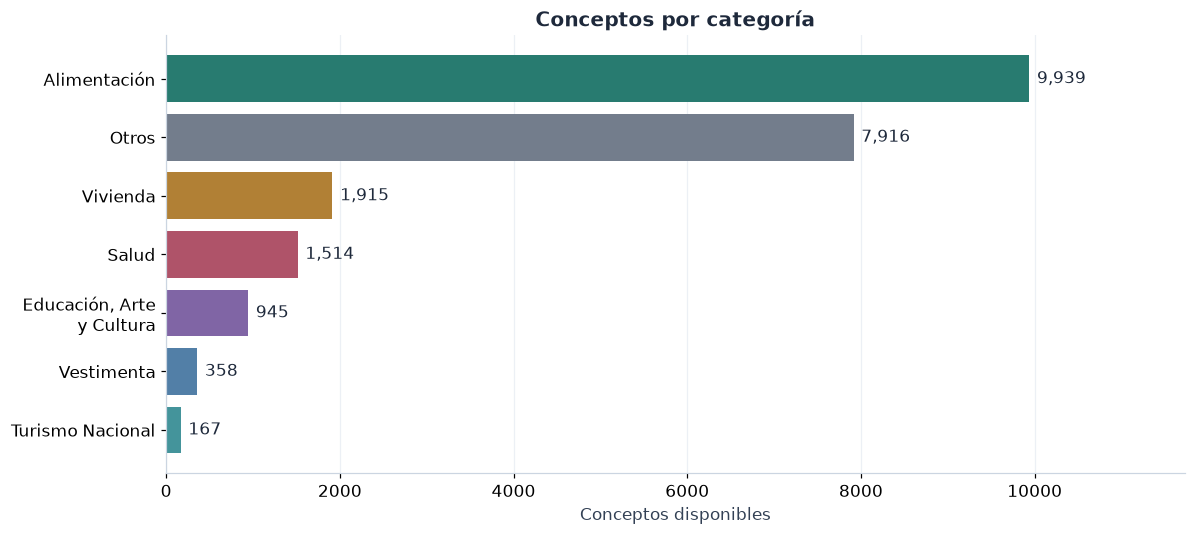

In [16]:
category_bars(
    class_profile["concepts"],
    "Conceptos por categoría",
    "Conceptos disponibles",
    "02_class_support",
)


In [17]:
display(
    class_profile.rename(
        columns={
            "concepts": "Conceptos",
            "invoices": "Facturas que la contienen",
            "unique_texts": "Textos únicos",
            "share_pct": "% de conceptos",
            "recurrence_pct": "% de apariciones adicionales",
        }
    ).round(2)
)

,Conceptos,Facturas que la contienen,Textos únicos,% de conceptos,% de apariciones adicionales
category,,,,,
Alimentación,9939,3039,4136,43.68,58.39
Otros,7916,3667,3359,34.79,57.57
Vivienda,1915,761,666,8.42,65.22
Salud,1514,890,852,6.65,43.73
"Educación, Arte y Cultura",945,218,592,4.15,37.35
Vestimenta,358,189,297,1.57,17.04
Turismo Nacional,167,164,42,0.73,74.85


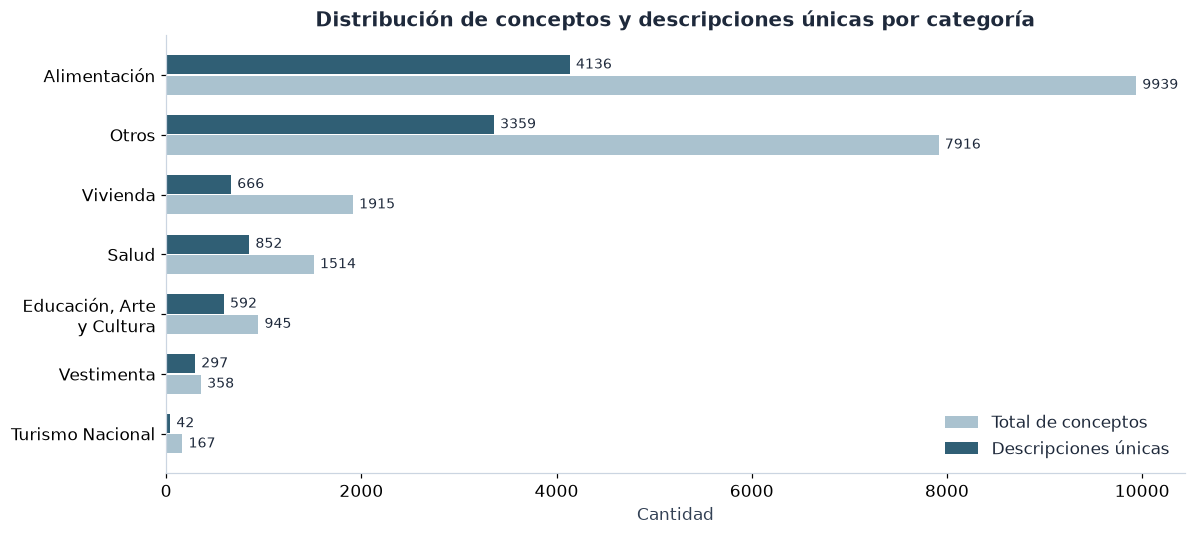

In [18]:
fig, ax = plt.subplots(figsize=(11, 5))
y = np.arange(len(class_profile))

bars_concepts = ax.barh(
    y + 0.17,
    class_profile["concepts"],
    height=0.32,
    color="#aac2cf",
    label="Total de conceptos",
)

bars_unique = ax.barh(
    y - 0.17,
    class_profile["unique_texts"],
    height=0.32,
    color="#305f75",
    label="Descripciones únicas",
)

ax.bar_label(
    bars_concepts,
    padding=4,
    fontsize=9,
    fmt="%.0f",
)
ax.bar_label(
    bars_unique,
    padding=4,
    fontsize=9,
    fmt="%.0f",
)
ax.set_yticks(y, [short_label(c) for c in class_profile.index])
ax.set(
    title="Distribución de conceptos y descripciones únicas por categoría",
    xlabel="Cantidad",
)
ax.invert_yaxis()
ax.legend(frameon=False)

generate_and_save_figure(fig, "03_support_and_diversity")

## 4. Comparación entre la frecuencia de conceptos y el gasto por categoría


El gasto por categoría se calculará sumando los importes de cada concepto después de descuentos y antes de impuestos, evitando utilizar el total de la factura, ya que este incluye otros valores que no corresponden directamente a cada línea. Para mantener la comparabilidad de los resultados, el análisis considerará únicamente las facturas cuya moneda esté identificada como USD, mientras que aquellas sin una denominación monetaria clara se excluirán del cálculo económico, pero permanecerán en los análisis de frecuencia y descripciones.


In [19]:
USD_NAMES = {
    "DOLAR",
    "DOLARES",
    "USD",
    "DOLLAR",
    "DOLLARS",
    "DOLAR AMERICANO",
    "DOLAR US",
    "US DOLLAR",
    "DOLAR USA",
    "US DOLARES",
}

In [10]:
invoices["currency_comparison_text"] = invoices["raw_currency"].map(comparison_text)
invoices["recognized_currency_code"] = invoices["currency_comparison_text"].map(
    lambda value: "USD" if value in USD_NAMES else pd.NA
)

money_invoice_ids = invoices.loc[invoices["recognized_currency_code"].eq("USD"), "source_file_id"]

invoice_items["line_total_float"] = invoice_items["line_total"].map(
    lambda value: float(value) if value is not None else np.nan
)

money_items = invoice_items.loc[
    invoice_items["source_file_id"].isin(money_invoice_ids)
].copy()

display(
    invoices.groupby(["raw_currency", "recognized_currency_code"], dropna=False)
    .size()
    .rename("Facturas")
    .reset_index()
)


,raw_currency,recognized_currency_code,Facturas
0,,NaN,44
1,DOL,NaN,4
2,DOLAR,USD,6685
3,DOLAR,USD,96
4,DOLAR AMERICANO,USD,32
5,DOLAR US,USD,7
6,DOLARES,USD,76
7,DOLARES DE LOS,NaN,3
8,DOLLAR,USD,5
9,Dolar,USD,76


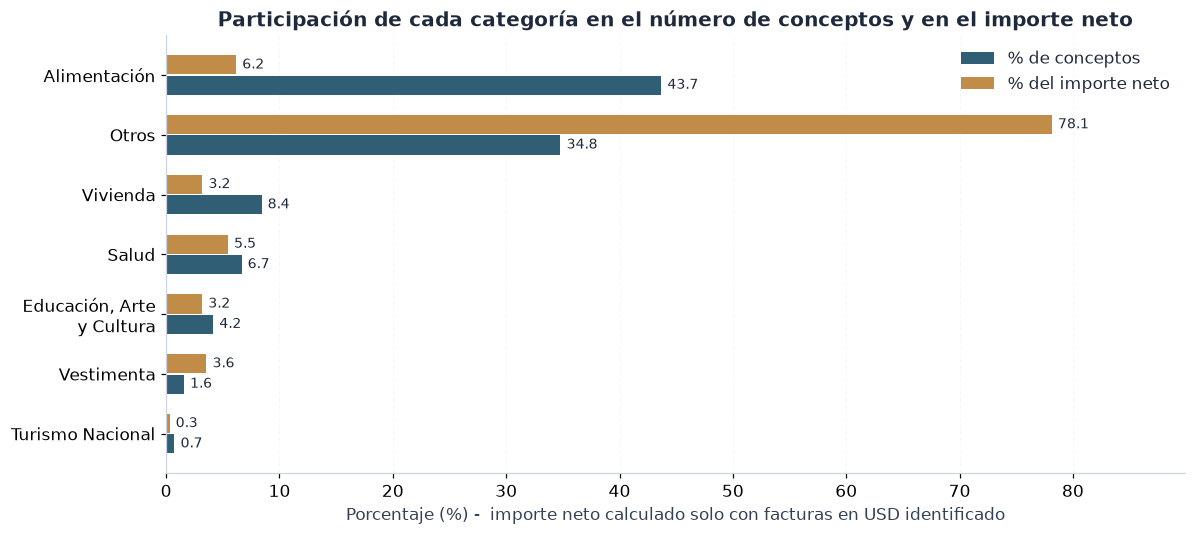

In [21]:
spending = (
    money_items.groupby("category", observed=True)["line_total"]
    .sum()
    .astype(float)
    .reindex(category_order)
)

spend_profile = pd.DataFrame(
    {
        "concept_share": class_profile["share_pct"],
        "spend_share": spending / spending.sum() * 100,
    }
)

fig, ax = plt.subplots(figsize=(11, 5))
y = np.arange(len(spend_profile))

bars_concepts = ax.barh(
    y + 0.17,
    spend_profile["concept_share"],
    height=0.32,
    color="#305f75",
    label="% de conceptos",
)

bars_spending = ax.barh(
    y - 0.17,
    spend_profile["spend_share"],
    height=0.32,
    color="#c08c48",
    label="% del importe neto",
)


ax.bar_label(
    bars_concepts,
    padding=4,
    fontsize=9,
    fmt="%.1f",
)
ax.bar_label(
    bars_spending,
    padding=4,
    fontsize=9,
    fmt="%.1f",
)

ax.set_yticks(y, [short_label(c) for c in spend_profile.index])
ax.set(
    title="Participación de cada categoría en el número de conceptos y en el importe neto",
    xlabel="Porcentaje (%) -  importe neto calculado solo con facturas en USD identificado",
)

max_value = max(
    spend_profile["concept_share"].max(),
    spend_profile["spend_share"].max(),
)

ax.set_xlim(0, max_value * 1.15)
ax.invert_yaxis()
ax.legend(frameon=False)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

generate_and_save_figure(fig, "04_volume_and_spending")

In [22]:
amount_profile = (
    money_items.groupby("category", observed=True)["line_total_float"]
    .agg(
        concepts="size",
        total="sum",
        median="median",
        p90=lambda s: s.quantile(0.90),
        maximum="max",
    )
    .reindex(category_order)
)

display(
    amount_profile.rename(
        columns={
            "concepts": "Conceptos",
            "total": "Importe neto USD",
            "median": "Mediana por concepto",
            "p90": "Percentil 90",
            "maximum": "Máximo",
        }
    ).round(2)
)

,Conceptos,Importe neto USD,Mediana por concepto,Percentil 90,Máximo
category,,,,,
Alimentación,9934,20900.37,1.22,4.78,86.00
Otros,7812,264376.89,2.13,16.96,39200.00
Vivienda,1900,10811.82,2.00,13.00,299.22
Salud,1512,18451.91,3.20,19.98,1300.00
"Educación, Arte y Cultura",942,10750.30,5.08,21.98,355.00
Vestimenta,357,12020.01,12.09,42.95,1645.00
Turismo Nacional,166,1029.88,3.70,9.80,308.62


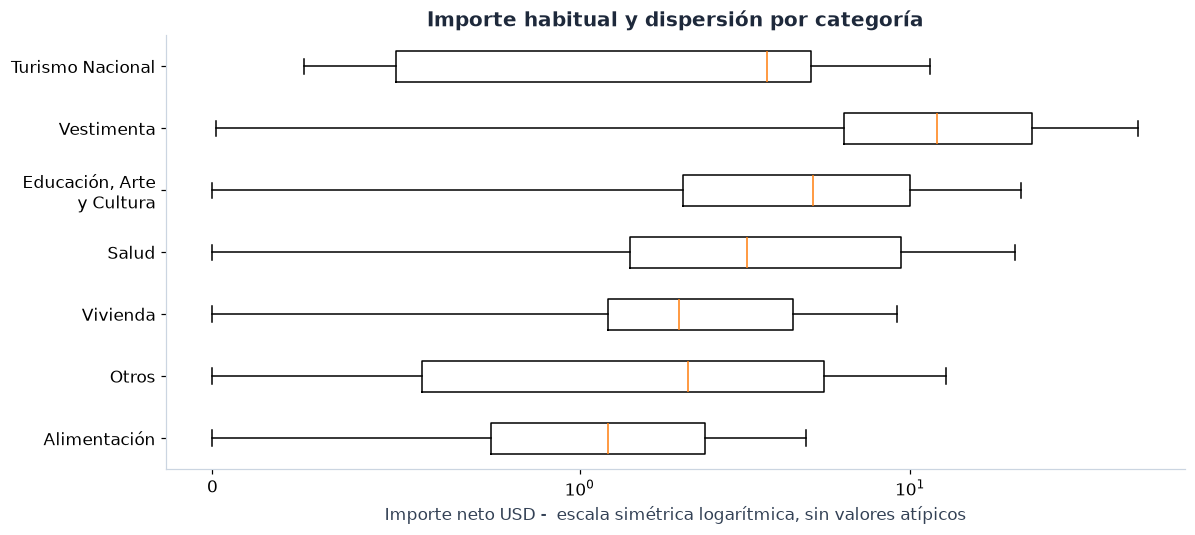

In [23]:
fig, ax = plt.subplots(figsize=(11, 5))

samples = [
    money_items.loc[money_items["category"].eq(c), "line_total_float"].dropna()
    for c in category_order
]

ax.boxplot(
    samples,
    orientation="horizontal",
    tick_labels=[short_label(c) for c in category_order],
    showfliers=False,
)
ax.set_xscale("symlog", linthresh=1)
ax.set(
    title="Importe habitual y dispersión por categoría",
    xlabel="Importe neto USD -  escala simétrica logarítmica, sin valores atípicos",
)

generate_and_save_figure(fig, "05_amount_distributions")

## 5. Evolución temporal de la composición de las compras


Las fechas reflejan únicamente el período cubierto por el conjunto de datos, incluyendo los meses sin registros y considerando que el último período puede estar incompleto.


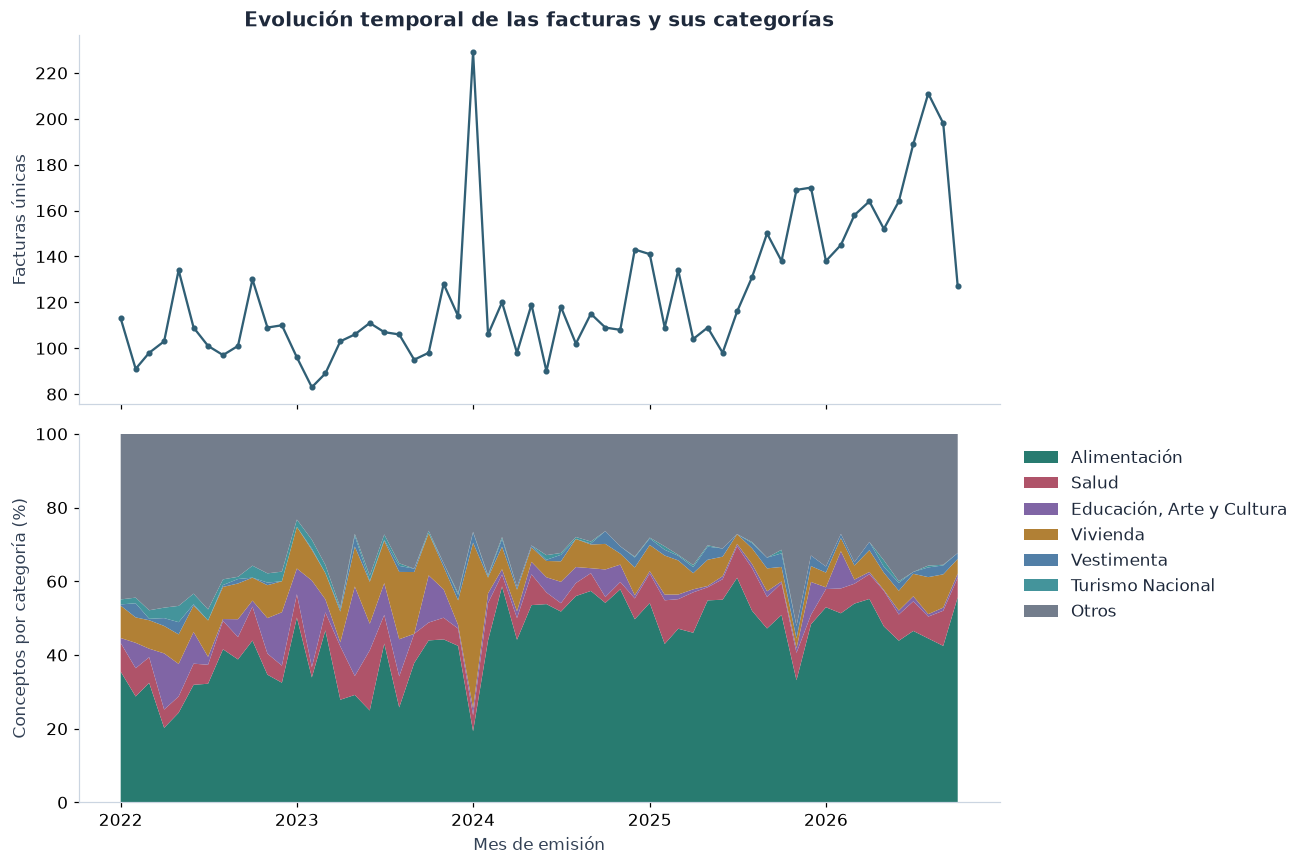

In [24]:
items = invoice_items.merge(
    invoices[["source_file_id", "issue_date", "raw_currency"]],
    on="source_file_id",
    validate="many_to_one",
)

monthly_index = pd.period_range(
    invoices["issue_date"].min(), invoices["issue_date"].max(), freq="M"
)
invoice_months = (
    invoices["issue_date"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
    .reindex(monthly_index, fill_value=0)
)
month_class = pd.crosstab(
    items["issue_date"].dt.to_period("M"), items["category"]
).reindex(monthly_index, fill_value=0)
month_shares = month_class.div(month_class.sum(axis=1).replace(0, np.nan), axis=0) * 100

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

dates = monthly_index.to_timestamp()

axes[0].plot(dates, invoice_months, color="#305f75", marker=".")
axes[0].set(
    title="Evolución temporal de las facturas y sus categorías",
    ylabel="Facturas únicas",
)
axes[1].stackplot(
    dates,
    [month_shares[c].fillna(0) for c in CATEGORIES],
    labels=CATEGORIES,
    colors=[COLORS[c] for c in CATEGORIES],
)
axes[1].set(
    ylabel="Conceptos por categoría (%)", ylim=(0, 100), xlabel="Mes de emisión"
)
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)

generate_and_save_figure(fig, "06_temporal_coverage")

In [25]:
last_date = invoices["issue_date"].max()
peak_month = invoice_months.idxmax()
peak_count = int(invoice_months.max())
typical_month = float(invoice_months.median())

annual = invoices.groupby(invoices["issue_date"].dt.year).agg(
    invoices=("source_file_id", "size"),
    first_date=("issue_date", "min"),
    last_date=("issue_date", "max"),
)
annual["first_date"] = annual["first_date"].dt.strftime("%d/%m/%Y")
annual["last_date"] = annual["last_date"].dt.strftime("%d/%m/%Y")

display(
    annual.rename(
        columns={
            "invoices": "Facturas",
            "first_date": "Primera fecha",
            "last_date": "Última fecha",
        }
    )
)


,Facturas,Primera fecha,Última fecha
issue_date,,,
2022,1296,01/01/2022,31/12/2022
2023,1236,02/01/2023,31/12/2023
2024,1457,01/01/2024,31/12/2024
2025,1569,02/01/2025,31/12/2025
2026,1646,02/01/2026,26/10/2026


## 6. Análisis de facturas con múltiples categorías


Se analiza la presencia de distintas categorías dentro de una misma factura, utilizando las descripciones de los demás conceptos como información de contexto. Para medir la asociación entre rubros se utiliza el índice de Jaccard, que relaciona la cantidad de facturas que contienen ambas categorías con aquellas que presentan al menos una de ellas.


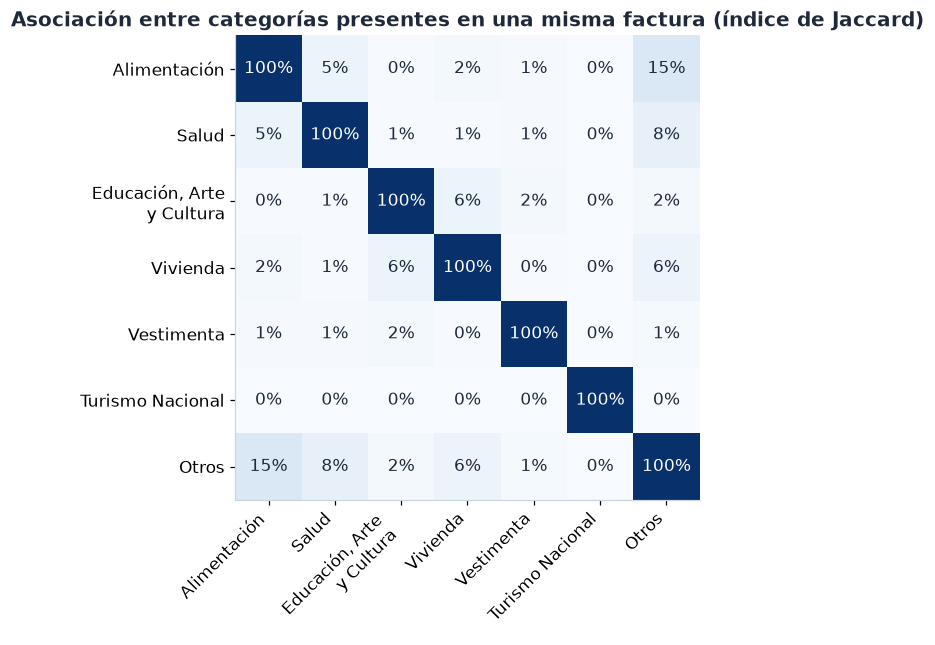

In [26]:
presence = (
    pd.crosstab(items["source_file_id"], items["category"])
    .gt(0)
    .astype(int)
    .reindex(columns=CATEGORIES)
)
invoice_category_count = presence.sum(axis=1)
intersection = presence.T.dot(presence)
counts = presence.sum()
union = (
    counts.to_numpy()[:, None] + counts.to_numpy()[None, :] - intersection.to_numpy()
)
jaccard = intersection.to_numpy() / union

fig, ax = plt.subplots(figsize=(10, 6))

image = ax.imshow(jaccard, cmap="Blues", vmin=0, vmax=1)

labels = [short_label(c) for c in CATEGORIES]

ax.set_xticks(range(7), labels, rotation=45, ha="right")
ax.set_yticks(range(7), labels)

for row in range(7):
    for col in range(7):
        ax.text(
            col,
            row,
            f"{jaccard[row, col]:.0%}",
            ha="center",
            va="center",
            color="white" if jaccard[row, col] > 0.6 else "#1e293b",
        )
ax.set_title(
    "Asociación entre categorías presentes en una misma factura (índice de Jaccard)"
)

generate_and_save_figure(fig, "07_category_cooccurrence")

## 7. Análisis de las características de las descripciones


Se analizan las características de las descripciones, considerando su longitud, los términos utilizados, la presencia de números, signos y marcadores de anonimización. Para comparar los textos se aplica una normalización que reduce las diferencias de escritura sin modificar las descripciones originales, conservando también los textos breves.


In [27]:
items["character_count"] = items["normalized_description"].str.len()
items["word_count"] = items["normalized_description"].map(
    lambda s: len(re.findall(r"[^\W_]+", s))
)
items["has_alphanumeric_description"] = items["normalized_description"].str.contains(
    r"[^\W_]"
)
items["has_anonymization_marker"] = items["raw_description"].str.contains(
    r"ANONIMIZAD[OA]", case=False, regex=True
)
items["default_word_tokens"] = items["normalized_description"].map(
    lambda s: len(re.findall(r"(?u)\b\w\w+\b", s))
)

text_profile = (
    items.groupby("category", observed=True)
    .agg(
        median_characters=("character_count", "median"),
        median_words=("word_count", "median"),
        short_share=("word_count", lambda s: s.le(2).mean() * 100),
        redaction_share=("has_anonymization_marker", lambda s: s.mean() * 100),
    )
    .reindex(category_order)
)

display(
    text_profile.rename(
        columns={
            "median_characters": "Mediana de caracteres",
            "median_words": "Mediana de palabras",
            "short_share": "% con hasta 2 palabras",
            "redaction_share": "% con marcas de anonimización",
        }
    ).round(2)
)

,Mediana de caracteres,Mediana de palabras,% con hasta 2 palabras,% con marcas de anonimización
category,,,,
Alimentación,19.0,4.0,20.86,0.00
Otros,20.0,4.0,27.16,1.09
Vivienda,23.0,4.0,24.23,0.00
Salud,25.0,4.0,17.64,0.00
"Educación, Arte y Cultura",28.0,4.0,7.72,0.63
Vestimenta,25.0,5.0,13.97,0.00
Turismo Nacional,19.0,3.0,44.31,4.19


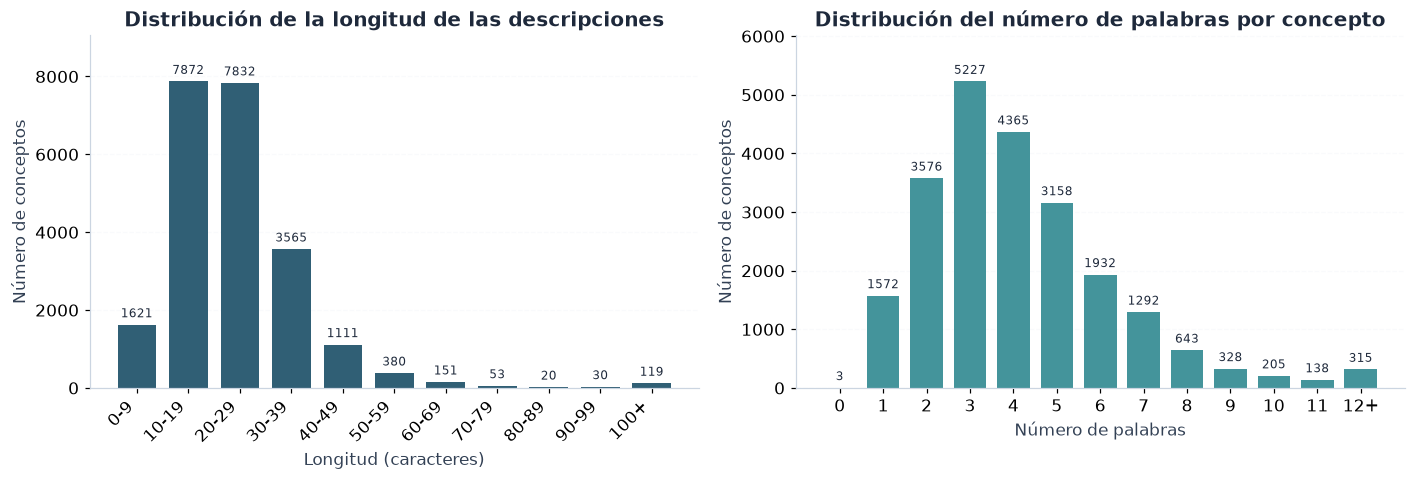

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

length_bins = list(range(0, 101, 10)) + [np.inf]

length_labels = [f"{i}-{i + 9}" for i in range(0, 100, 10)] + ["100+"]

length_distribution = (
    pd.cut(
        items["character_count"],
        bins=length_bins,
        labels=length_labels,
        right=False,
        include_lowest=True,
    )
    .value_counts()
    .sort_index()
)
bars_length = axes[0].bar(
    range(len(length_distribution)),
    length_distribution.values,
    color="#305f75",
    width=0.75,
)

axes[0].set_xticks(range(len(length_labels)), length_labels, rotation=45, ha="right")
axes[0].set(
    title="Distribución de la longitud de las descripciones",
    xlabel="Longitud (caracteres)",
    ylabel="Número de conceptos",
)
axes[0].bar_label(bars_length, padding=3, fontsize=8, fmt="%.0f")
axes[0].set_ylim(0, length_distribution.max() * 1.15)

word_distribution = (
    items["word_count"].clip(upper=12).value_counts().reindex(range(13), fill_value=0)
)
bars_words = axes[1].bar(
    word_distribution.index, word_distribution.values, color="#44949b", width=0.75
)

axes[1].set_xticks(range(13), [str(i) for i in range(12)] + ["12+"])
axes[1].set(
    title="Distribución del número de palabras por concepto",
    xlabel="Número de palabras",
    ylabel="Número de conceptos",
)
axes[1].bar_label(bars_words, padding=3, fontsize=8, fmt="%.0f")
axes[1].set_ylim(0, word_distribution.max() * 1.15)

for ax in axes:
    ax.grid(axis="y", linestyle="--", alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()

generate_and_save_figure(fig, "08_description_lengths")

In [29]:
punctuation_count = int((~items["has_alphanumeric_description"]).sum())
redaction_count = int(items["has_anonymization_marker"].sum())

In [30]:
def other_descriptions(group: pd.DataFrame) -> pd.Series:
    """Conserva las otras líneas en su orden, sin añadir sus categorías."""
    texts = group["raw_description"].tolist()
    values = [" | ".join(texts[:i] + texts[i + 1 :]) for i in range(len(texts))]

    return pd.Series(values, index=group.index, dtype="string")

In [31]:
context_parts = [
    other_descriptions(group) for _, group in items.groupby("source_file_id", sort=False)
]

items["other_items_raw_description_text"] = pd.concat(context_parts).reindex(items.index)

text_examples = (
    items.loc[
        ~items["has_alphanumeric_description"] | items["has_anonymization_marker"],
        ["raw_description", "category", "additional_item_attributes", "other_items_raw_description_text"],
    ]
    .drop_duplicates("raw_description")
    .head()
    .copy()
)

for column in ["additional_item_attributes", "other_items_raw_description_text"]:
    text_examples[column] = text_examples[column].str.slice(0, 120)

display(
    text_examples.rename(
        columns={
            "raw_description": "Descripción observada",
            "category": "Categoría",
            "additional_item_attributes": "Atributos (extracto)",
            "other_items_raw_description_text": "Otras líneas (extracto)",
        }
    )
)

,Descripción observada,Categoría,Atributos (extracto),Otras líneas (extracto)
174,MERCANCIA PREMIER/Guía:[NUMERO_DE_GUÍA_ANONIMI...,Otros,ENVIOS: [VALOR_ANONIMIZADO] | PORCENTAJE: [VAL...,
650,<Factura No.>[CUENTA_ANONIMIZADO] <POLIZA-No....,Otros,,
2470,MERCANCIA PREMIER/Guía:[LICENCIA_ANONIMIZADO],Otros,ENVIOS: [VALOR_ANONIMIZADO] | PORCENTAJE: [VAL...,
2773,-----------------------------,Otros,,FD MAICE TOSC 200 | SB GELA S ROYA | LIB QUESO...
2982,FUNDAS BURBUJA 14*18/Guía:[NUMERO_DE_GUÍA_ANON...,Otros,ENVIOS: [VALOR_ANONIMIZADO] | PORCENTAJE: [VAL...,MERCANCIA PREMIER/Guía:[LICENCIA_ANONIMIZADO]


## 8. Análisis del vocabulario y las expresiones por categoría


Se analiza el vocabulario característico de cada categoría mediante el recuento de palabras y pares de palabras consecutivas, considerando cada descripción distinta una sola vez para evitar que las compras repetidas influyan excesivamente en los resultados. Este análisis permite identificar términos y expresiones frecuentes en determinados rubros.


In [32]:
lexical_documents = (
    items.drop_duplicates(["description_comparison_text", "category"]).copy().reset_index(drop=True)
)

connectors = {
    "de",
    "del",
    "la",
    "el",
    "los",
    "las",
    "y",
    "en",
    "para",
    "con",
    "por",
    "a",
    "un",
    "una",
    "al",
}

In [33]:
def text_expressions(value: str) -> set[str]:
    """Extrae palabras y pares de palabras consecutivas, ignorando conectores y palabras de una sola letra."""
    words = re.findall(r"[^\W_]+", value.lower())
    unigrams = {w for w in words if w not in connectors and len(w) > 1}

    bigrams = {
        " ".join(pair)
        for pair in itertools.pairwise(words)
        if not set(pair).issubset(connectors)
    }

    return unigrams | bigrams

In [34]:
lexical_documents["expressions"] = lexical_documents["normalized_description"].map(
    text_expressions
)

expression_counts = {
    category: Counter(term for terms in group["expressions"] for term in terms)
    for category, group in lexical_documents.groupby("category", observed=True)
}

all_expression_counts = sum(expression_counts.values(), Counter())

In [35]:
distinctive_rows = []

for category, counts in expression_counts.items():
    group_size = int(lexical_documents["category"].eq(category).sum())
    outside_size = len(lexical_documents) - group_size
    candidates = []

    for term, count in counts.items():
        if count < 2:
            continue

        within = count / group_size
        outside = (all_expression_counts[term] - count + 1) / (outside_size + 1)

        candidates.append((within / outside, term, count, within * 100))

    for lift, term, count, rate in sorted(candidates, reverse=True)[:5]:
        distinctive_rows.append(
            {
                "category": category,
                "expression": term,
                "texts": count,
                "rate": rate,
                "lift": lift,
            }
        )

distinctive = pd.DataFrame(distinctive_rows)

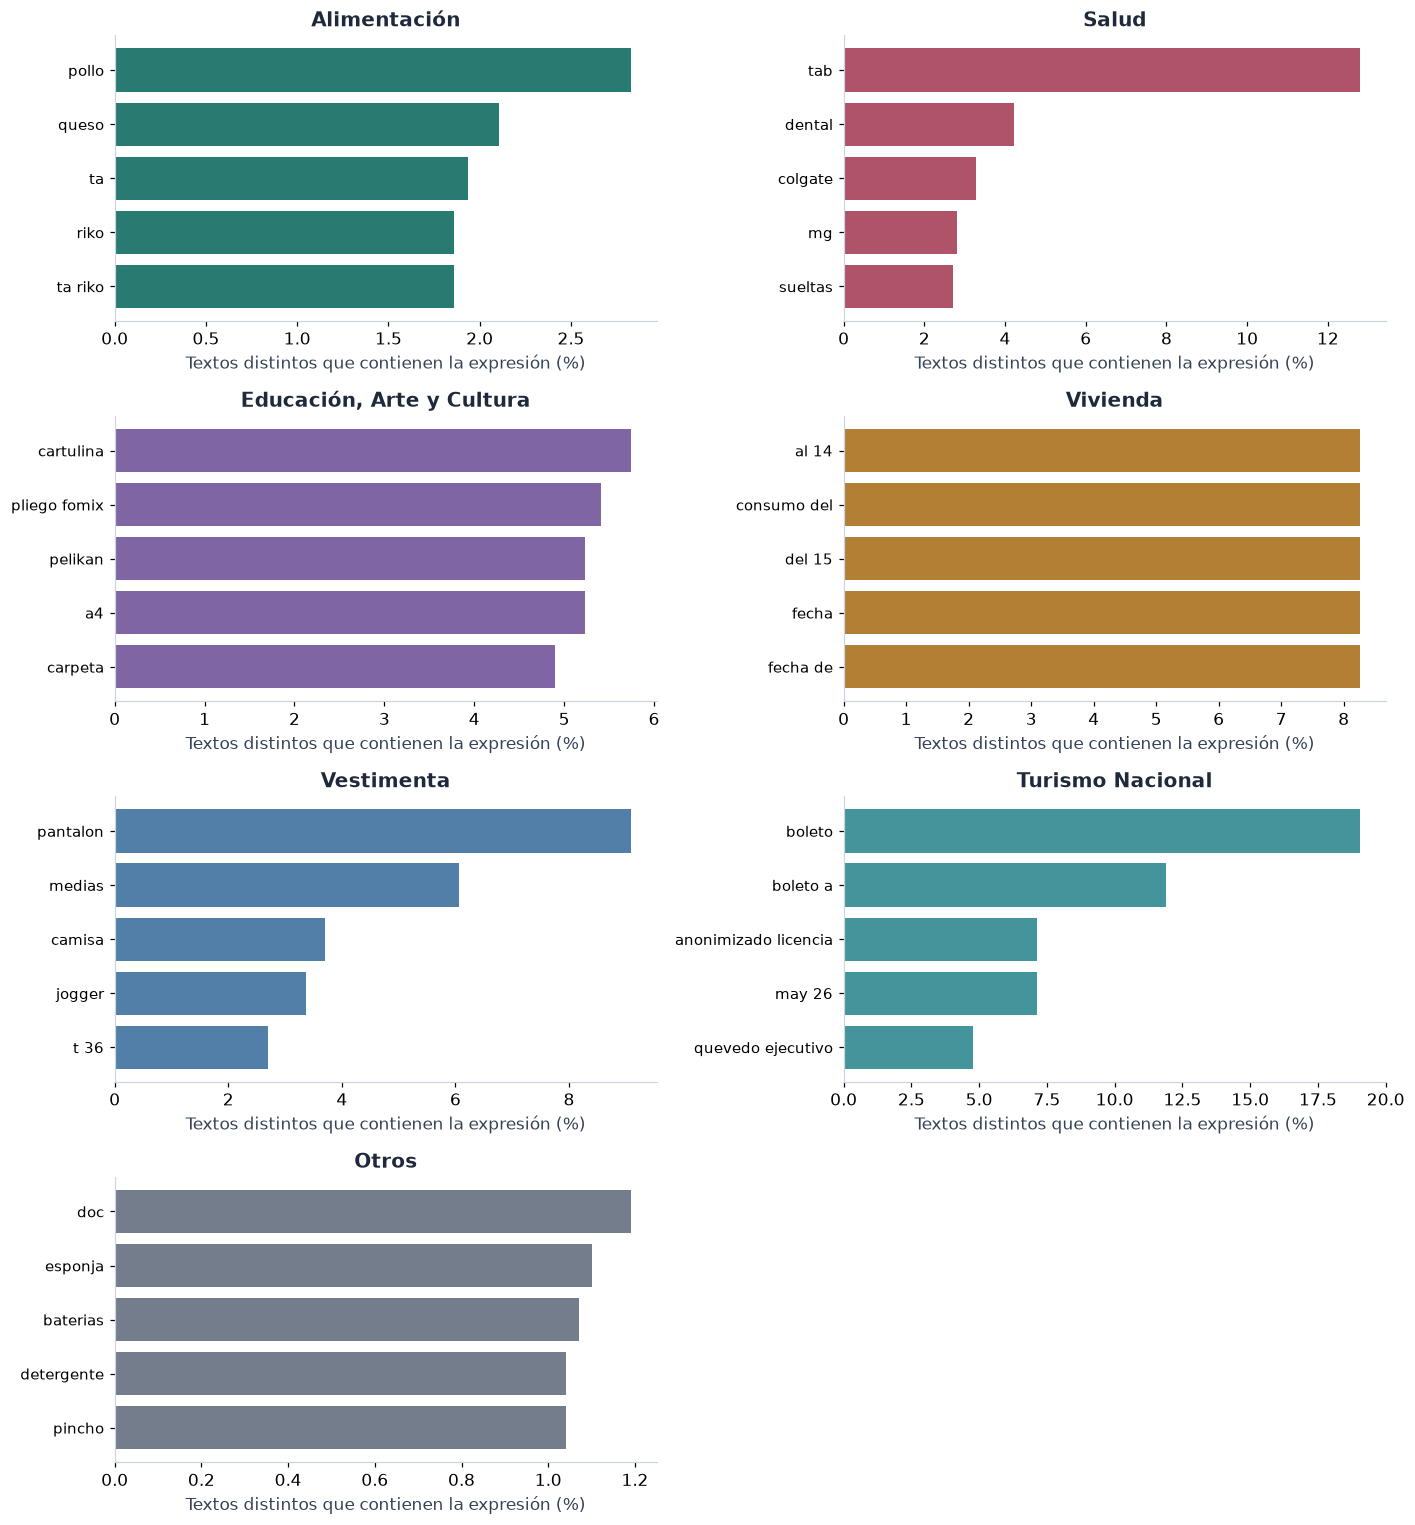

In [36]:
fig, axes = plt.subplots(4, 2, figsize=(13, 14))

for ax, category in zip(axes.flat, CATEGORIES):
    subset = distinctive.loc[distinctive["category"].eq(category)].sort_values("rate")

    ax.barh(subset["expression"], subset["rate"], color=COLORS[category])
    ax.set(title=category, xlabel="Textos distintos que contienen la expresión (%)")
    ax.tick_params(axis="y", labelsize=10)

axes.flat[-1].set_visible(False)

generate_and_save_figure(fig, "09_distinctive_expressions")

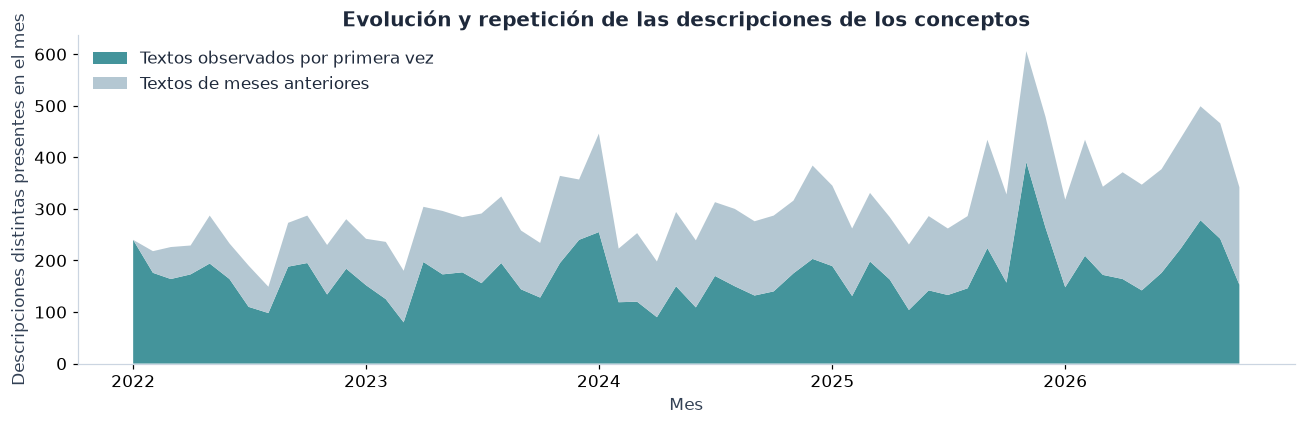

In [37]:
first_month = items.groupby("description_comparison_text")["issue_date"].min().dt.to_period("M")
new_types = first_month.value_counts().sort_index().reindex(monthly_index, fill_value=0)
monthly_types = (
    items.groupby(items["issue_date"].dt.to_period("M"))["description_comparison_text"]
    .nunique()
    .reindex(monthly_index, fill_value=0)
)
known_types = monthly_types - new_types

fig, ax = plt.subplots(figsize=(12, 4))

ax.stackplot(
    dates,
    new_types,
    known_types,
    labels=["Textos observados por primera vez", "Textos de meses anteriores"],
    colors=["#44949b", "#b4c7d2"],
)
ax.set(
    title="Evolución y repetición de las descripciones de los conceptos",
    xlabel="Mes",
    ylabel="Descripciones distintas presentes en el mes",
)
ax.legend(frameon=False, loc="upper left")

generate_and_save_figure(fig, "10_vocabulary_recurrence")

## 9. Análisis de las características lingüísticas con spaCy


Se utiliza el modelo `es_core_news_sm` de spaCy para analizar las características lingüísticas de las descripciones, incluyendo lemas, categorías gramaticales, relaciones sintácticas y entidades nombradas, procesando cada texto distinto una sola vez.


In [38]:
nlp = spacy.load("es_core_news_sm")

unique_descriptions = sorted(items["normalized_description"].unique())
documents = list(nlp.pipe(unique_descriptions, batch_size=128))
doc_by_text = dict(zip(unique_descriptions, documents))

print(
    f"spaCy {spacy.__version__} - modelo {nlp.meta['version']} - {len(documents):,} textos analizados."
)

spaCy 3.8.18 - modelo 3.8.0 - 10,023 textos analizados.


In [39]:
linguistic_rows = []

for text, doc in doc_by_text.items():
    content = [token for token in doc if not token.is_space and not token.is_punct]

    linguistic_rows.append(
        {
            "normalized_description": text,
            "lemma_text": " ".join(token.lemma_.lower() for token in content),
            "noun_count": sum(token.pos_ in {"NOUN", "PROPN"} for token in content),
            "verb_count": sum(token.pos_ in {"VERB", "AUX"} for token in content),
            "entity_count": len(doc.ents),
            "noun_phrases": " | ".join(chunk.text for chunk in doc.noun_chunks),
        }
    )

linguistic = pd.DataFrame(linguistic_rows)

linguistic_items = items.merge(
    linguistic, on="normalized_description", validate="many_to_one"
)

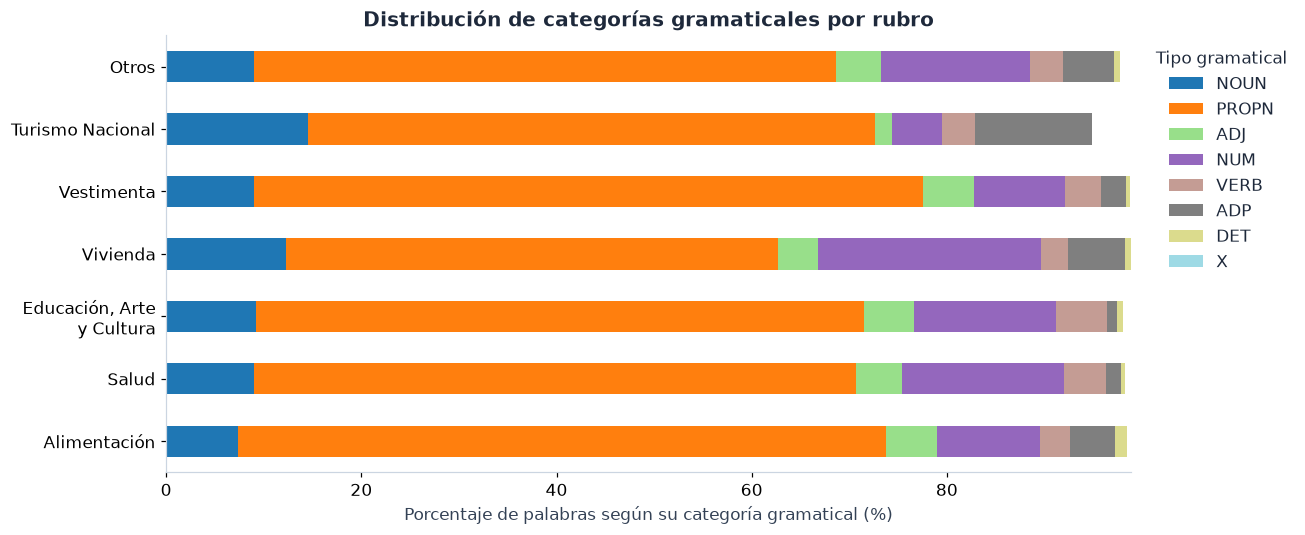

In [40]:
pos_rows = []

for category, group in lexical_documents.groupby("category", observed=True):
    counts = Counter(
        token.pos_
        for text in group["normalized_description"]
        for token in doc_by_text[text]
        if not token.is_space and not token.is_punct
    )

    total = sum(counts.values())

    pos_rows.extend(
        {"category": category, "pos": pos, "share": count / total * 100}
        for pos, count in counts.items()
    )

pos_profile = (
    pd.DataFrame(pos_rows)
    .pivot(index="category", columns="pos", values="share")
    .fillna(0)
)

pos_columns = [
    c
    for c in ["NOUN", "PROPN", "ADJ", "NUM", "VERB", "ADP", "DET", "X"]
    if c in pos_profile
]

fig, ax = plt.subplots(figsize=(12, 5))

pos_profile.reindex(CATEGORIES)[pos_columns].plot.barh(
    stacked=True, ax=ax, colormap="tab20"
)

ax.set_yticklabels([short_label(c) for c in CATEGORIES])
ax.set(
    title="Distribución de categorías gramaticales por rubro",
    xlabel="Porcentaje de palabras según su categoría gramatical (%)",
    ylabel="",
)
ax.legend(title="Tipo gramatical", bbox_to_anchor=(1.01, 1), frameon=False)

generate_and_save_figure(fig, "11_part_of_speech")

In [41]:
syntax_profile = linguistic_items.groupby("category", observed=True).agg(
    with_nouns=("noun_count", lambda s: s.gt(0).mean() * 100),
    with_verbs=("verb_count", lambda s: s.gt(0).mean() * 100),
    with_entities=("entity_count", lambda s: s.gt(0).mean() * 100),
)

display(
    syntax_profile.rename(
        columns={
            "with_nouns": "% con sustantivos o nombres propios",
            "with_verbs": "% con verbos",
            "with_entities": "% con entidades detectadas",
        }
    ).round(1)
)

,% con sustantivos o nombres propios,% con verbos,% con entidades detectadas
category,,,
Alimentación,97.9,10.6,91.5
"Educación, Arte y Cultura",99.2,21.8,87.7
Otros,97.5,13.6,86.7
Salud,97.3,19.4,90.4
Turismo Nacional,95.8,3.6,94.6
Vestimenta,99.2,15.9,89.7
Vivienda,92.6,9.3,85.8


In [42]:
example_text = lexical_documents.sort_values("word_count", ascending=False).iloc[0][
    "normalized_description"
]

example_doc = doc_by_text[example_text]

display(
    pd.DataFrame(
        [
            {
                "Texto": t.text,
                "Lema": t.lemma_,
                "Tipo": t.pos_,
                "Relación": t.dep_,
                "Depende de": t.head.text,
            }
            for t in example_doc
            if not t.is_space
        ]
    ).head()
)

,Texto,Lema,Tipo,Relación,Depende de
0,POSESIÓN,posesión,NOUN,ROOT,POSESIÓN
1,EFECTIVA,efectivo,ADJ,amod,POSESIÓN
2,PARA,PARA,ADP,case,RETIROS
3,RETIROS,RETIROS,PROPN,nmod,POSESIÓN
4,DE,DE,ADP,case,MONTEPÍOS


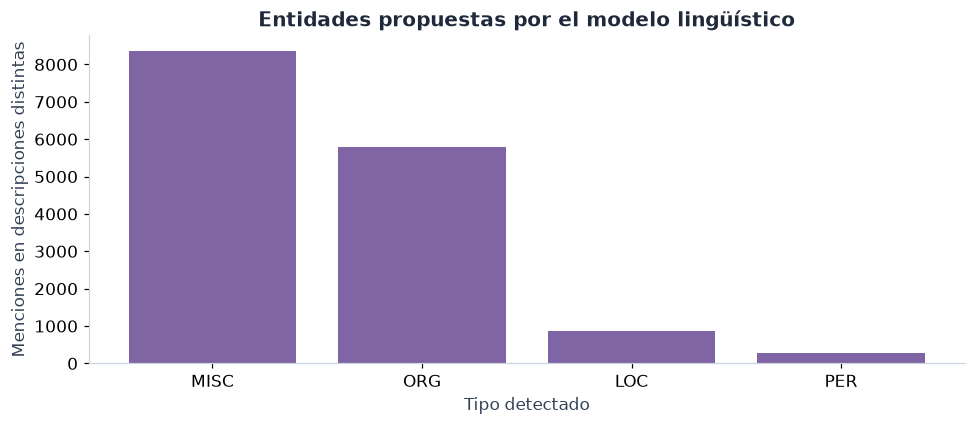

In [43]:
entity_rows = [
    {"normalized_description": text, "entity": entity.text, "entity_type": entity.label_}
    for text, doc in doc_by_text.items()
    for entity in doc.ents
]
entities = pd.DataFrame(
    entity_rows, columns=["normalized_description", "entity", "entity_type"]
)
entity_counts = entities["entity_type"].value_counts()

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(entity_counts.index, entity_counts.values, color="#8065a5")
ax.set(
    title="Entidades propuestas por el modelo lingüístico",
    xlabel="Tipo detectado",
    ylabel="Menciones en descripciones distintas",
)

generate_and_save_figure(fig, "12_detected_entities")

In [44]:
display(
    entities.drop_duplicates(["entity", "entity_type"])
    .head(12)
    .rename(
        columns={
            "normalized_description": "Descripción",
            "entity": "Entidad propuesta",
            "entity_type": "Tipo propuesto",
        }
    )
)

,Descripción,Entidad propuesta,Tipo propuesto
0,'ALICATE CORTE DIAGONAL 7'' BED/BDHT8158,ALICATE,MISC
1,'ALICATE CORTE DIAGONAL 7'' BED/BDHT8158,BDHT8158,ORG
2,(1) CERTIFICACIÓN DE DOCUMENTOS EXHIBIDOS EN C...,(1) CERTIFICACIÓN,LOC
3,(1) CERTIFICACIÓN DE DOCUMENTOS EXHIBIDOS EN C...,DOCUMENTOS EXHIBIDOS,MISC
4,(1) CERTIFICACIÓN DE DOCUMENTOS EXHIBIDOS EN C...,COPIAS,MISC
7,(1) CERTIFICACIÓN DE DOCUMENTOS EXHIBIDOS EN O...,ORIGINAL,MISC
11,(1) CERTIFICACIÓN DE DOCUMENTOS EXHIBIDOS EN O...,CERTIFICADA,ORG
12,(1) CERTIFICACIÓN DE DOCUMENTOS EXHIBIDOS EN O...,SE INCORPOREN A,ORG
15,(1) CERTIFICACIÓN DE DOCUMENTOS EXHIBIDOS EN O...,ORIGINALES O,MISC
17,(1) CERTIFICACIÓN DE DOCUMENTOS MATERIALIZADOS...,DOCUMENTOS,ORG


## 10. Análisis de similitud semántica entre descripciones


Se utiliza el modelo multilingüe preentrenado `paraphrase-multilingual-MiniLM-L12-v2` para representar las descripciones mediante embeddings y analizar su similitud semántica (cada descripción distinta se procesa una sola vez), identificando agrupaciones de textos y posibles coincidencias entre categorías.

Los embeddings se obtienen mediante el promedio de las representaciones de los tokens, considerando la máscara de atención, y se normalizan para calcular la similitud coseno.


In [45]:
import torch
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from transformers import AutoModel, AutoTokenizer

EMBEDDING_MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
EMBEDDING_REVISION = "e8f8c211226b894fcb81acc59f3b34ba3efd5f42"

device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(EMBEDDING_MODEL, revision=EMBEDDING_REVISION)
semantic_model = (
    AutoModel.from_pretrained(EMBEDDING_MODEL, revision=EMBEDDING_REVISION)
    .to(device)
    .eval()
)

print(f"Semántica: {device} - revisión {semantic_model.config._commit_hash}")

Semántica: cuda - revisión e8f8c211226b894fcb81acc59f3b34ba3efd5f42


In [46]:
def encode_descriptions(
    texts: list[str], model, tokenizer, batch_size: int = 64
) -> np.ndarray:
    """Calcula embeddings con pesos fijos y promedio de tokens no vacíos."""
    batches = []
    for start in range(0, len(texts), batch_size):
        batch = texts[start : start + batch_size]
        encoded = tokenizer(
            batch, padding=True, truncation=True, max_length=128, return_tensors="pt"
        ).to(device)

        with torch.inference_mode():
            output = model(**encoded).last_hidden_state
            mask = encoded["attention_mask"].unsqueeze(-1).to(output.dtype)
            pooled = (output * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
            normalized = torch.nn.functional.normalize(pooled, p=2, dim=1)

        batches.append(normalized.cpu().numpy())

    return np.concatenate(batches)


In [47]:
semantic_texts = lexical_documents["normalized_description"].tolist()
embeddings = encode_descriptions(semantic_texts, semantic_model, tokenizer)

print(
    f"Semántica completada: {embeddings.shape[0]:,} textos de {embeddings.shape[1]} dimensiones."
)

Semántica completada: 9,944 textos de 384 dimensiones.


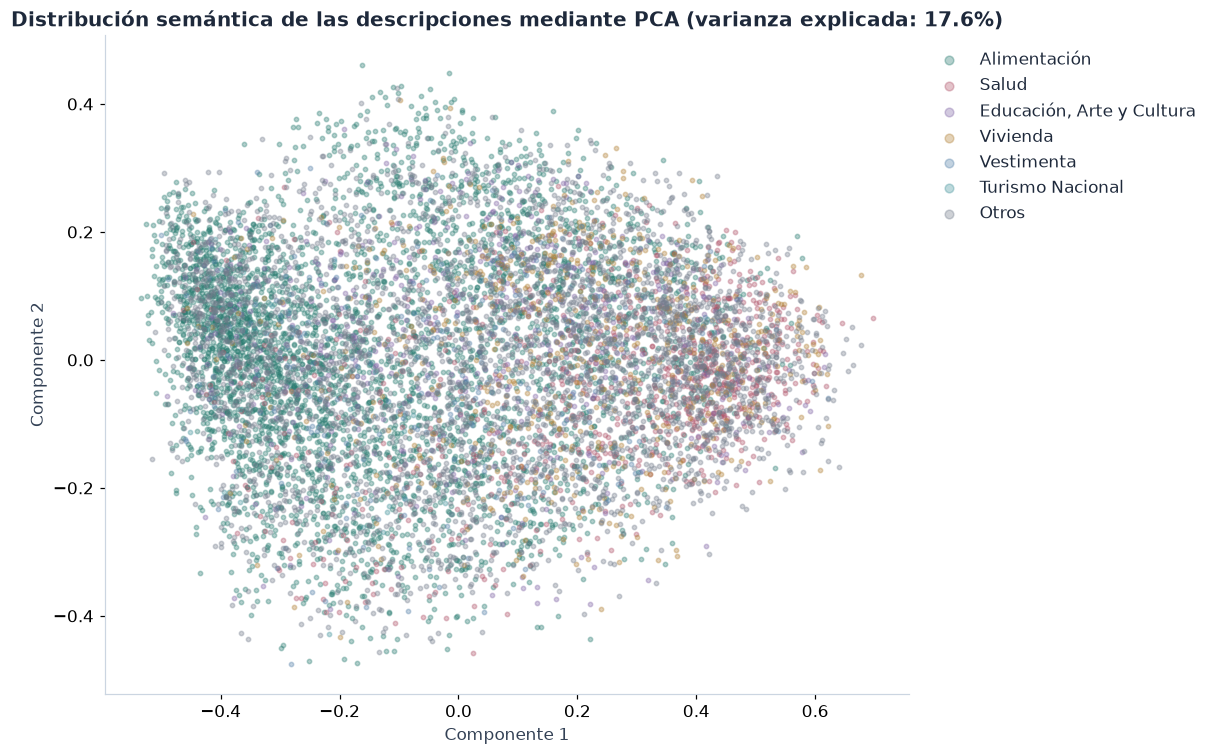

In [48]:
# Usamos PCA para reducir la dimensionalidad a 2D
# y visualizar las relaciones semánticas entre las
# descripciones de los conceptos.
projection = PCA(n_components=2, random_state=42)
coordinates = projection.fit_transform(embeddings)

fig, ax = plt.subplots(figsize=(11, 7))

for category in CATEGORIES:
    selected = lexical_documents["category"].eq(category).to_numpy()

    ax.scatter(
        coordinates[selected, 0],
        coordinates[selected, 1],
        s=8,
        alpha=0.35,
        color=COLORS[category],
        label=category,
    )

explained = projection.explained_variance_ratio_.sum() * 100

ax.set(
    title=f"Distribución semántica de las descripciones mediante PCA (varianza explicada: {explained:.1f}%)",
    xlabel="Componente 1",
    ylabel="Componente 2",
)
ax.legend(bbox_to_anchor=(1.01, 1), frameon=False, markerscale=2)

generate_and_save_figure(fig, "13_semantic_projection")

In [49]:
centroids, cohesion_rows = [], []

for category in CATEGORIES:
    selected = lexical_documents["category"].eq(category).to_numpy()
    group_embeddings = embeddings[selected]
    
    centroid = group_embeddings.mean(axis=0)
    centroid = centroid / np.linalg.norm(centroid)
    centroids.append(centroid)
    
    cohesion_rows.append(
        {
            "Categoría": category,
            "Textos distintos": int(selected.sum()),
            "Proximidad media al centro": float((group_embeddings @ centroid).mean()),
        }
    )
    
semantic_similarity = np.stack(centroids) @ np.stack(centroids).T

cohesion = pd.DataFrame(cohesion_rows).set_index("Categoría")

display(cohesion.round(3))

,Textos distintos,Proximidad media al centro
Categoría,,
Alimentación,4136,0.645
Salud,852,0.629
"Educación, Arte y Cultura",592,0.664
Vivienda,666,0.629
Vestimenta,297,0.632
Turismo Nacional,42,0.694
Otros,3359,0.599


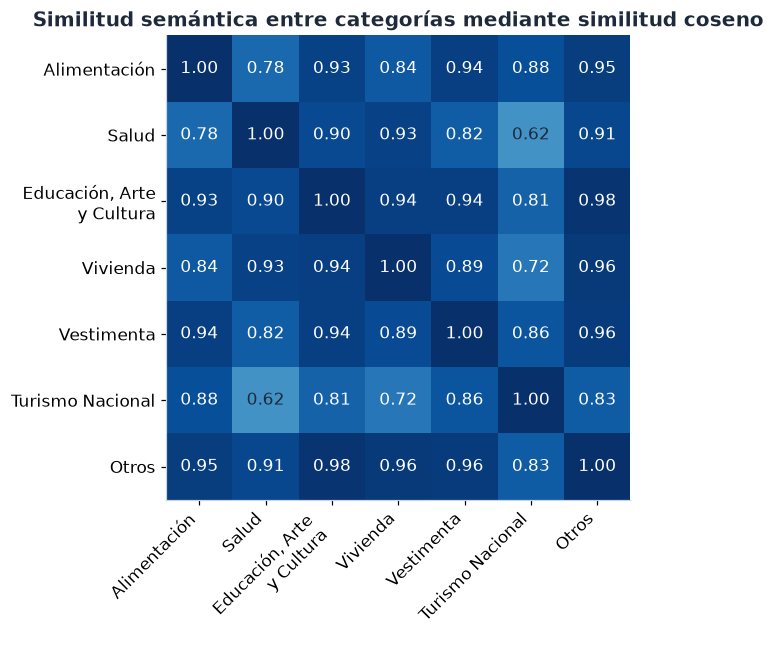

In [50]:
fig, ax = plt.subplots(figsize=(10, 6))
image = ax.imshow(semantic_similarity, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(7), [short_label(c) for c in CATEGORIES], rotation=45, ha="right")
ax.set_yticks(range(7), [short_label(c) for c in CATEGORIES])

for row in range(7):
    for col in range(7):
        value = semantic_similarity[row, col]

        ax.text(
            col,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if value > 0.65 else "#1e293b",
        )

ax.set_title("Similitud semántica entre categorías mediante similitud coseno")

generate_and_save_figure(fig, "14_semantic_category_proximity")

In [51]:
neighbors = NearestNeighbors(n_neighbors=3, metric="cosine").fit(embeddings)
distances, neighbor_indices = neighbors.kneighbors(embeddings)
nearest_other = [
    next((distance, other) for distance, other in zip(d, indices) if other != index)
    for index, (d, indices) in enumerate(zip(distances, neighbor_indices))
]

pair_rows = []

for category in CATEGORIES:
    indices = np.flatnonzero(lexical_documents["category"].eq(category).to_numpy())
    index = min(indices, key=lambda i: nearest_other[i][0])
    distance, other = nearest_other[index]

    pair_rows.append(
        {
            "Texto": semantic_texts[index],
            "Categoría": category,
            "Texto próximo": semantic_texts[other],
            "Categoría vecina": lexical_documents.iloc[other]["category"],
            "Similitud coseno": round(float(1 - distance), 3),
        }
    )

display(pd.DataFrame(pair_rows))

,Texto,Categoría,Texto próximo,Categoría vecina,Similitud coseno
0,ALIMENTO HUMEDO P/GATO NUTRAPRO SACHET 85 G SA...,Alimentación,ALIMENTO HUMEDO P/GATO NUTRAPRO 85 G SALMON RE...,Alimentación,0.996
1,X RAY DOL TABx250/220/65MGx48,Salud,X RAY DOL TABx250/220/65MGx12,Salud,0.997
2,PLIEGO FOMIX 60X115 NEGRO PURO,"Educación, Arte y Cultura",PLIEGO FOMIX NEGRO PURO 60X115,"Educación, Arte y Cultura",0.996
3,Plan PL2 - Pago del servicio del mes (2026-07-...,Vivienda,Plan PL2 - Pago del servicio del mes (2026-08-...,Vivienda,0.998
4,CAMISETA CAB BASIC,Vestimenta,CAMISETA CAB BASICA,Vestimenta,0.992
5,SERVICIO DE TRANSPORTE: CUENCA - GUAYAQUIL,Turismo Nacional,SERVICIO DE TRANSPORTE: GUAYAQUIL - CUENCA,Turismo Nacional,0.996
6,UÑAS POSTIZAS PINTADAS EN CAJA DE LUJO,Otros,UÑAS POSTIZAS PINTADAS DE LUJO EN CAJA,Otros,0.999


In [52]:
del semantic_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()

## 11. Análisis de los resultados y conclusiones


### 11.1. La unidad de análisis y la calidad de su estructura

La entrada contiene 7.225 archivos y 22.796 conceptos etiquetados, pero no todos los archivos representan compras distintas. Al retirar las 21 copias exactas, que contienen 42 conceptos, la base de datos queda en 7.204 facturas y 22.754 conceptos.

Las comprobaciones de integridad no detectaron incidencias relacionadas con categorías faltantes o inválidas, identificadores de línea duplicados, conceptos sin factura ni fechas o importes netos que no pudieran interpretarse.

La disponibilidad de información complementaria varía entre categorías, aunque el código principal está presente en casi todos los conceptos. El código auxiliar alcanza una cobertura aproximada del 85 % en «Educación, Arte y Cultura» frente al 43 % en «Vestimenta», mientras que los atributos adicionales presentan diferencias mayores, con un 71 % en la primera categoría y apenas un 3 % en «Alimentación».

### 11.2. Diferencias entre la cantidad de conceptos y la diversidad de descripciones por categoría

«Alimentación» concentra 9.939 conceptos (43,68 %) y «Otros» 7.916 (34,79 %), reuniendo entre ambas el 78,47 % del conjunto, mientras que «Turismo Nacional» y «Vestimenta» presentan las menores participaciones, con 167 (0,73 %) y 358 (1,57 %) conceptos, respectivamente. Esta distribución muestra un marcado desequilibrio, con aproximadamente 59,5 veces más ejemplos de «Alimentación» que de «Turismo Nacional», lo que podría favorecer a las categorías mayoritarias en la evaluación global del clasificador.

La diversidad de descripciones también presenta diferencias entre categorías, como ocurre con «Turismo Nacional», que registra 42 textos distintos entre 167 conceptos, con un 74,85 % de apariciones repetidas, y «Vivienda», con 666 descripciones entre 1.915 conceptos y un 65,22 % de repetición. En contraste, «Vestimenta» presenta 297 textos distintos entre 358 conceptos, con apenas un 17,04 % de repetición, lo que muestra que, aunque «Turismo Nacional» y «Vestimenta» cuentan con pocos ejemplos, esta última presenta una mayor diversidad textual proporcional.

La categoría «Otros» está presente en 3.667 facturas, frente a las 3.039 de «Alimentación», aunque esta última reúne más conceptos. Asimismo, los 945 conceptos de «Educación, Arte y Cultura» se distribuyen en 218 facturas, mientras que los 167 de «Turismo Nacional» aparecen en 164, mostrando diferencias en la concentración de conceptos por comprobante y la importancia de considerar que las líneas de una misma factura comparten contexto.

### 11.3. Diferencias entre la frecuencia de conceptos y su participación en el gasto por categoría

El análisis económico considera 22.623 conceptos de facturas con moneda identificada como USD, excluyendo 131 conceptos de 57 comprobantes cuya moneda no pudo determinarse con certeza, como «DOL», «US» o «DOLARES DE LOS». Estos registros permanecen en los análisis de frecuencia y texto, por lo que los porcentajes de conceptos se calculan sobre 22.754 líneas, mientras que los de gasto utilizan únicamente los importes con moneda identificada.

En la base monetaria comparable, «Otros» concentra 264.376,89 USD, equivalente al 78,1 % del importe neto, pese a representar el 34,79 % de los conceptos, mientras que «Alimentación» reúne el 43,68 % de las líneas, pero apenas el 6,2 % del gasto, con 20.900,37 USD.

«Vestimenta» representa apenas el 1,57 % de los conceptos, pero presenta una mediana de 12,09 USD, superior a los 1,22 USD de «Alimentación», mientras que «Salud» registra una mediana de 3,20 USD y un máximo de 1.300 USD.

### 11.4. Evolución temporal de las facturas y su distribución por categorías

Las facturas abarcan del 1 de enero de 2022 al 26 de octubre de 2026, con 1.296 registros en 2022, 1.236 en 2023, 1.457 en 2024, 1.569 en 2025 y 1.646 en 2026. El mayor registro mensual se presentó en enero de 2024, con 229 facturas frente a una mediana de 112, acompañado de una menor participación relativa de «Alimentación» y un aumento de «Vivienda».


### 11.5. Influencia del contexto de la factura en la clasificación de conceptos

Se identificaron 1.509 facturas con conceptos de distintas categorías, equivalentes al 20,9 % de los 7.204 comprobantes analizados, lo que señala que una misma factura pueda contabilizarse en varios rubros. El índice de Jaccard muestra una mayor asociación entre «Alimentación» y «Otros» (15 %), seguida de «Salud» y «Otros» (8 %) y «Educación, Arte y Cultura» y «Vivienda» (6 %), porcentajes que representan la proporción de facturas compartidas respecto al total de comprobantes que contienen al menos una de las dos categorías comparadas.


### 11.6. Descripciones breves y datos anonimizados

Las descripciones presentan medianas de entre 19 y 28 caracteres y de tres a cinco palabras según la categoría, con diferencias en la proporción de textos breves, que alcanza el 44,31 % en «Turismo Nacional» frente al 7,72 % en «Educación, Arte y Cultura». Esta variación muestra que si se pretende excluir descripciones por su longitud afectaría especialmente a las categorías menos representadas, ya que los textos cortos si pueden identificar productos o servicios válidos y no necesariamente reflejan información insuficiente.

Solo tres descripciones carecen de letras y números, entre ellas una formada por guiones cuya factura contiene otros conceptos, como «FD MAICE TOSC 200», «SB GELA S ROYA» y «LIB QUESO», que podrían aportar información para su revisión.

Se identificaron marcadores de anonimización en 99 conceptos, con una mayor proporción en «Turismo Nacional» (4,19 %), seguida de «Otros» (1,09 %) y «Educación, Arte y Cultura» (0,63 %), lo que resulta especialmente relevante en categorías con pocos ejemplos. Estas descripciones pueden conservar información útil junto con fragmentos anonimizados, como «MERCANCIA PREMIER/Guía:…».

### 11.7. Análisis del vocabulario característico y los patrones de escritura por categoría

El análisis considera una sola vez cada descripción normalizada por categoría para reducir la influencia de las compras repetidas y examinar la diversidad del vocabulario. Entre los términos característicos destacan *pollo* y *queso* en «Alimentación», *tab* y *mg* en «Salud», *cartulina* y *pliego fomix* en *Educación, Arte y Cultura*, así como *pantalon* y *medias* en *Vestimenta*.

La selección de expresiones se basa en su presencia relativa dentro de cada categoría frente a las demás, aplicando suavizado y exigiendo al menos dos textos, sin priorizar los términos más frecuentes del conjunto. Por ejemplo, *pollo* aparece en menos del 3 % de las descripciones distintas de «Alimentación», mientras que *boleto* alcanza cerca del 19 % en «Turismo Nacional», una categoría con solo 42 textos diferentes. En «Vivienda» destacan expresiones como *al 14*, *del 15*, *fecha* y *consumo del*, asociadas a formatos de facturación periódica, mientras que en «Turismo Nacional» aparecen referencias como *may 26* y fragmentos derivados de la anonimización. 

### 11.8. Resultados del análisis lingüístico

Al procesar con spaCy se obtuvo 10.023 descripciones distintas tras normalizar Unicode y espacios, frente a los 9.944 textos utilizados en los análisis léxico y semántico, donde se agruparon otras variantes de escritura. Además, el análisis gramatical considera los tokens de los textos distintos, mientras que la presencia de sustantivos, verbos y entidades se calcula sobre las 22.754 apariciones. De la misma forma, la presencia de sustantivos o nombres propios varía entre el 92,6 % y el 99,2 % de los conceptos según la categoría, mientras que los verbos aparecen con menor frecuencia, desde el 3,6 % en «Turismo Nacional» hasta el 21,8 % en «Educación, Arte y Cultura».

Por otra parte, las entidades nombradas se detectaron en entre el 85,8 % y el 94,6 % de los conceptos según la categoría, aunque se observaron identificaciones incorrectas, como *BDHT8158* clasificado como organización, *(1) CERTIFICACIÓN* como lugar y *SE INCORPOREN A* como organización.

### 11.9. Análisis semántico y separación entre categorías

El análisis semántico representó 9.944 descripciones mediante vectores de 384 dimensiones obtenidos de un modelo multilingüe preentrenado, cuya reducción a dos componentes mediante PCA explicó únicamente el 17,6 % de la varianza.

La categoría «Otros» presenta la menor similitud media con su centro semántico (0,599), frente a «Turismo Nacional» (0,694) y «Educación, Arte y Cultura» (0,664), lo que indica una mayor diversidad de productos y servicios dentro de este rubro. Aunque «Turismo Nacional» muestra una mayor cohesión, esta se basa en apenas 42 descripciones distintas, considerando además que el análisis no incluye medidas de incertidumbre.

La similitud entre los centros semánticos de «Educación, Arte y Cultura» y «Otros» alcanza 0,98, mientras que entre «Vivienda» y «Otros» es de 0,96, lo que muestra una elevada proximidad entre sus representaciones promedio, sin indicar probabilidades de confusión ni porcentajes de acierto.

Los pares de descripciones analizados presentan similitudes entre 0,992 y 0,999, con diferencias en aspectos como el tamaño de los envases, el orden de las palabras, las fechas de los servicios o las rutas de transporte.

### 11.10. Conclusiones

El análisis exploratorio mostró un marcado desequilibrio entre las categorías, con una mayor concentración de conceptos en «Alimentación» y «Otros», mientras que «Turismo Nacional» y «Vestimenta» presentan una representación considerablemente menor. También se identificaron diferencias en la diversidad de descripciones, ya que algunas categorías tienen varias compras con textos repetidos, mientras que otras presentan una mayor variedad de expresiones en relación con su cantidad de conceptos.

Las descripciones se caracterizan por su brevedad, el uso frecuente de mayúsculas, abreviaturas, códigos y unidades, además de diferencias en la disponibilidad de información complementaria. El análisis lingüístico mostró el predominio de estructuras nominales y algunas limitaciones de spaCy para interpretar textos comerciales, mientras que el análisis semántico identificó relaciones entre categorías y una mayor heterogeneidad interna en «Otros».

Asimismo, se observaron diferencias entre la frecuencia de las compras y su participación económica, variaciones temporales en la composición de los comprobantes y la presencia de facturas con conceptos de distintos rubros. En conjunto, estos resultados describen que eln conjunto de datos es heterogéneo, tanto en su distribución como en sus características textuales y económicas, y permiten reconocer las particularidades de la información disponible para la clasificación de conceptos.